# M04-L04 — CNNs Clássicas: LeNet, AlexNet, VGG e ResNet
## Laboratório do participante

**Antes de começar:**

1. Abra este notebook no Google Colab e salve uma cópia no Drive.
2. Carregaremos do Drive o `dataset_iris` balanceado e dividido em `train`, `val` e `test` na M04-L03. Tenha também `comparacao_cnn_vs_mlp_m04l03.csv` salvo no Drive ou disponível para upload.
3. Nesta lição, as mesmas imagens serão redimensionadas para **64 × 64**. Isso é necessário porque a AlexNet reduz várias vezes as dimensões espaciais e não consegue processar a entrada `32 × 32` usada pela CNN simples da L03.
4. `torchvision.models` fornece **arquiteturas já implementadas**. Isso não significa que elas já estejam treinadas.
5. Usaremos `weights=None`: a estrutura da rede vem pronta, mas os **pesos começam aleatórios**. Pesos pré-treinados serão assunto da M04-L06.
6. Execute as células na ordem. Os exercícios de análise pedem que você use o `print(modelo)` e os diagramas do `content.md` como evidência.

> **Ideia central:** nesta lição você deixa de decidir cada `Conv2d` manualmente. Primeiro inspeciona uma arquitetura pronta, depois localiza a parte que precisa ser adaptada para as 3 classes de Iris.


## 1. Retomando o dataset balanceado da M04-L03

O conjunto de imagens e a divisão treino/validação/teste **não mudam**. Na M04-L03, você salvou `dataset_iris/train`, `val` e `test` em `Meu Drive/dados_modulo_04/dataset_iris`. Monte o mesmo Drive na célula abaixo: o Colab carregará as imagens diretamente dessa pasta. Se estiver usando outra conta ou não encontrar a pasta, compacte a pasta `dataset_iris` salva anteriormente em um arquivo `dataset_iris.zip` e faça o upload quando solicitado. Não baixe nem rebalanceie o conjunto bruto nesta lição.

Apenas criamos novos `DataLoader`s com `Resize((64, 64))` para que as arquiteturas desta lição consigam processar as imagens.


In [1]:
from pathlib import Path
import zipfile
import torch
from google.colab import drive, files
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

drive.mount('/content/drive')
base_dir = Path('/content/drive/MyDrive/dados_modulo_04/dataset_iris')
if not base_dir.is_dir():
    print('Pasta dataset_iris não encontrada no Drive. Envie dataset_iris.zip da M04-L03.')
    enviados = files.upload()
    if 'dataset_iris.zip' not in enviados:
        raise FileNotFoundError('Envie dataset_iris.zip com as partições train, val e test da M04-L03.')
    with zipfile.ZipFile('/content/dataset_iris.zip') as arquivo_zip:
        if any(nome.startswith('/') or '..' in Path(nome).parts for nome in arquivo_zip.namelist()):
            raise ValueError('O ZIP contém caminhos inválidos.')
        arquivo_zip.extractall('/content')
    base_dir = Path('/content/dataset_iris')

classes_esperadas = {'setosa', 'versicolor', 'virginica'}
for particao in ('train', 'val', 'test'):
    pasta = base_dir / particao
    if not pasta.is_dir() or {x.name for x in pasta.iterdir() if x.is_dir()} != classes_esperadas:
        raise FileNotFoundError(f'Confira as três classes em {pasta}. Use o dataset balanceado da M04-L03.')

transform_modelos_classicos = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

dataset_treino = datasets.ImageFolder(base_dir / "train", transform=transform_modelos_classicos)
dataset_val = datasets.ImageFolder(base_dir / "val", transform=transform_modelos_classicos)
dataset_teste = datasets.ImageFolder(base_dir / "test", transform=transform_modelos_classicos)

BATCH_SIZE = 16
loader_treino = DataLoader(dataset_treino, batch_size=BATCH_SIZE, shuffle=True)
loader_val = DataLoader(dataset_val, batch_size=BATCH_SIZE, shuffle=False)
loader_teste = DataLoader(dataset_teste, batch_size=BATCH_SIZE, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

imagens_exemplo, rotulos_exemplo = next(iter(loader_treino))
print("Classes:", dataset_treino.classes)
print("Shape de um batch:", imagens_exemplo.shape)
print("Dispositivo:", device)


Mounted at /content/drive
Classes: ['setosa', 'versicolor', 'virginica']
Shape de um batch: torch.Size([16, 3, 64, 64])
Dispositivo: cpu


## 2. Retomada rápida dos resultados anteriores

Na M04-L03, a tabela com a acurácia da `CNNIrisSimples` e os resultados da MLP foi salva como `comparacao_cnn_vs_mlp_m04l03.csv` em `Meu Drive/dados_modulo_04/`. Vamos ler esse mesmo arquivo, sem recalcular a CNN. Se ele não estiver no Drive, envie o CSV gerado ao final da M04-L03 quando a célula solicitar. A comparação final depende desse arquivo; não continue com uma tabela vazia.


In [2]:
import pandas as pd

nome_resultados_l03 = 'comparacao_cnn_vs_mlp_m04l03.csv'
arquivo_resultados = Path('/content/drive/MyDrive/dados_modulo_04') / nome_resultados_l03
if not arquivo_resultados.is_file():
    print(f'{nome_resultados_l03} não encontrado no Drive. Envie o CSV da M04-L03.')
    enviados = files.upload()
    if nome_resultados_l03 not in enviados:
        raise FileNotFoundError(f'Envie {nome_resultados_l03} antes de continuar.')
    arquivo_resultados = Path('/content') / nome_resultados_l03

resultados = pd.read_csv(arquivo_resultados)
if not {'modelo', 'acuracia_teste'}.issubset(resultados.columns):
    raise ValueError('O CSV da M04-L03 precisa ter as colunas modelo e acuracia_teste.')
if not resultados['modelo'].astype(str).str.contains('CNNIrisSimples', regex=False).any():
    raise ValueError('O CSV precisa conter a linha da CNNIrisSimples da M04-L03.')
display(resultados)


,modelo,acuracia_teste
0,LogisticRegression,NaN
1,DecisionTreeClassifier,NaN
2,KNeighborsClassifier,NaN
3,MLP escolhida — Mais larga (5→16→3),1.000000
4,MLP escolhida regularizada — Mais larga (5→16→3),1.000000
5,CNNIrisSimples (imagem direta),0.393939


## 3. Antes do código: o que vem "pronto" em `torchvision.models`?

Uma chamada como `alexnet(weights=None)` entrega um objeto `nn.Module` cuja **arquitetura já foi implementada** por quem mantém o TorchVision.

Isso inclui, por exemplo:

- a sequência de camadas;
- quantos canais entram e saem de cada convolução;
- onde existem operações de pooling;
- como o classificador final é organizado;
- o método `forward` que conecta tudo.

Mas `weights=None` significa que os valores internos dessas camadas começam **aleatórios**. Portanto:

**arquitetura pronta ≠ rede já treinada.**

Ao executar `print(modelo)`, você consegue enxergar essa arquitetura como uma árvore de módulos. Os exercícios a seguir existem justamente para aprender a ler essa árvore.


## 4. Exemplo guiado 1 — Instanciando e inspecionando a AlexNet original

Antes de adaptar qualquer coisa, vamos criar a AlexNet exatamente como o `torchvision.models` a fornece com `weights=None`.

Compare o `print` com o diagrama:

![Diagrama da AlexNet](https://drive.google.com/thumbnail?id=1Cixniok4R4YAOkdZe9swbOpT-OdK54yM&sz=w1600)

In [3]:
from torchvision.models import alexnet

alexnet_base = alexnet(weights=None)
print(alexnet_base)


AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

In [4]:
def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())

print("Total de parâmetros da AlexNet:", contar_parametros(alexnet_base))
print("Primeira convolução:", alexnet_base.features[0])
print("Última camada:", alexnet_base.classifier[6])


Total de parâmetros da AlexNet: 61100840
Primeira convolução: Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
Última camada: Linear(in_features=4096, out_features=1000, bias=True)


### Exercício 1 — Lendo a AlexNet como um todo

Use **somente o `print(alexnet_base)` acima e o diagrama** para responder:

1. Quais são os três grandes blocos que aparecem no `print` (`features`, `avgpool` e `classifier`)? Qual parece ser o papel de cada um?
2. Quantas camadas `Conv2d` aparecem dentro de `features`?
3. Quantas operações `MaxPool2d` aparecem dentro de `features`?
4. Quantas camadas `Linear` aparecem dentro de `classifier`?
5. Qual é a entrada e a saída da **primeira** `Conv2d` (`in_channels` e `out_channels`)?
6. Quantas saídas a última `Linear` possui originalmente?
7. O `print` bate com o diagrama didático? Cite pelo menos **duas correspondências**.
8. O diagrama do artigo original de 2012 é idêntico ao `print` atual do TorchVision? Consulte a figura indicada no `content.md` e registre uma diferença que você percebeu.

**Sua resposta:**

1. `features`: convoluções, ReLU e pooling que extraem características da imagem. `avgpool`: padroniza o tamanho espacial, dando 9216 valores. `classifier`: camadas Linear que transformam essas características em pontuações por classe.
2. 5 Conv2d.
3. 3 MaxPool2d.
4. 3 Linear.
5. `in_channels=3` e `out_channels=64`.
6. 1000 saídas.
7. Sim. As correspondências são os locais das figuras e o que deviam estar naquele lugar e os poolings.
8. Não é idêntico. A versão original de 2012 foi dividida em dois fluxos paralelos, em duas GPUs, e usava normalização de resposta local (LRN). Agora, essa versão do TorchVision é um fluxo único, sem LRN e com menos filtros. O print ainda inclui uma camada AdaptiveAvgPool2d, que não aparece na figura original.

## 5. Exemplo guiado 2 — Criando a `AlexNetIrisAdaptada`

Agora criamos **outro objeto** para deixar claro que ele representa a versão adaptada para o problema de Iris.

Observe o nome: `alexnet_iris_adaptada`, e não apenas `alexnet`.


In [5]:
import torch.nn as nn

alexnet_iris_adaptada = alexnet(weights=None)

n_entradas_ultima_camada = alexnet_iris_adaptada.classifier[6].in_features
alexnet_iris_adaptada.classifier[6] = nn.Linear(n_entradas_ultima_camada, 3)

print(alexnet_iris_adaptada)
print("\nCamada final adaptada:", alexnet_iris_adaptada.classifier[6])


AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

In [6]:
alexnet_iris_adaptada = alexnet_iris_adaptada.to(device)

uma_imagem = imagens_exemplo[:1].to(device)
alexnet_iris_adaptada.eval()
with torch.no_grad():
    saida_antes_treino = alexnet_iris_adaptada(uma_imagem)

print("Shape da saída:", saida_antes_treino.shape)
print("Valores:", saida_antes_treino.cpu())


Shape da saída: torch.Size([1, 3])
Valores: tensor([[ 0.0056,  0.0007, -0.0091]])


### Exercício 2 — O que a adaptação realmente mudou?

Compare o `print(alexnet_base)` com o `print(alexnet_iris_adaptada)`:

1. Qual camada mudou?
2. O `in_features` dessa camada mudou?
3. O `out_features` mudou de quanto para quanto?
4. Quantas `Conv2d` mudaram por causa da adaptação?
5. Por que a saída do teste acima tem shape `[1, 3]`?
6. Por que esses três valores ainda não podem ser tratados como uma boa classificação, mesmo que a arquitetura esteja corretamente adaptada?

**Sua resposta:**

1. A última camada.
2. Não.
3. Mudou de 1000 para 3.
4. Nenhuma mudou, só a camada final mesmo.
5. Porque a entrada tem 1 imagem e a rede produz 3 saídas.
6. Porque os pesos ainda são aleatórios e a rede não foi treinada.


## 6. Exemplo guiado 3 — Treinando a `AlexNetIrisAdaptada`

A estrutura do treino é a mesma da M04-L03. Agora a rede inteira começa com pesos aleatórios e aprende com as imagens de Iris.


In [7]:
import torch.optim as optim

criterio = nn.CrossEntropyLoss()
otimizador_alexnet = optim.Adam(alexnet_iris_adaptada.parameters(), lr=1e-4)

historico_alexnet = {"epoca": [], "perda_treino": [], "acc_treino": [], "perda_val": [], "acc_val": []}

n_epocas = 15
for epoca in range(1, n_epocas + 1):
    alexnet_iris_adaptada.train()
    perda_total, acertos, total = 0.0, 0, 0

    for imagens, rotulos in loader_treino:
        imagens, rotulos = imagens.to(device), rotulos.to(device)
        otimizador_alexnet.zero_grad()
        saidas = alexnet_iris_adaptada(imagens)
        perda = criterio(saidas, rotulos)
        perda.backward()
        otimizador_alexnet.step()

        perda_total += perda.item() * imagens.size(0)
        acertos += (saidas.argmax(dim=1) == rotulos).sum().item()
        total += imagens.size(0)

    perda_treino = perda_total / total
    acc_treino = acertos / total

    alexnet_iris_adaptada.eval()
    perda_val_total, acertos_val, total_val = 0.0, 0, 0
    with torch.no_grad():
        for imagens, rotulos in loader_val:
            imagens, rotulos = imagens.to(device), rotulos.to(device)
            saidas = alexnet_iris_adaptada(imagens)
            perda = criterio(saidas, rotulos)
            perda_val_total += perda.item() * imagens.size(0)
            acertos_val += (saidas.argmax(dim=1) == rotulos).sum().item()
            total_val += imagens.size(0)

    perda_val = perda_val_total / total_val
    acc_val = acertos_val / total_val

    historico_alexnet["epoca"].append(epoca)
    historico_alexnet["perda_treino"].append(perda_treino)
    historico_alexnet["acc_treino"].append(acc_treino)
    historico_alexnet["perda_val"].append(perda_val)
    historico_alexnet["acc_val"].append(acc_val)

    print(f"Época {epoca}: perda_treino={perda_treino:.4f} acc_treino={acc_treino:.4f} "
          f"perda_val={perda_val:.4f} acc_val={acc_val:.4f}")


Época 1: perda_treino=1.1030 acc_treino=0.3116 perda_val=1.0989 acc_val=0.3333
Época 2: perda_treino=1.0985 acc_treino=0.3551 perda_val=1.0986 acc_val=0.3333
Época 3: perda_treino=1.0999 acc_treino=0.3043 perda_val=1.0986 acc_val=0.3333
Época 4: perda_treino=1.1009 acc_treino=0.2536 perda_val=1.0986 acc_val=0.3333
Época 5: perda_treino=1.1013 acc_treino=0.2681 perda_val=1.0988 acc_val=0.3333
Época 6: perda_treino=1.1002 acc_treino=0.3043 perda_val=1.0988 acc_val=0.3333
Época 7: perda_treino=1.0986 acc_treino=0.3406 perda_val=1.0984 acc_val=0.3333
Época 8: perda_treino=1.0987 acc_treino=0.3406 perda_val=1.0975 acc_val=0.5000
Época 9: perda_treino=1.0963 acc_treino=0.3986 perda_val=1.0974 acc_val=0.3667
Época 10: perda_treino=1.0849 acc_treino=0.4638 perda_val=1.0767 acc_val=0.4000
Época 11: perda_treino=1.0619 acc_treino=0.4493 perda_val=1.0730 acc_val=0.4333
Época 12: perda_treino=0.9747 acc_treino=0.5362 perda_val=1.0795 acc_val=0.3667
Época 13: perda_treino=0.8415 acc_treino=0.5870 p

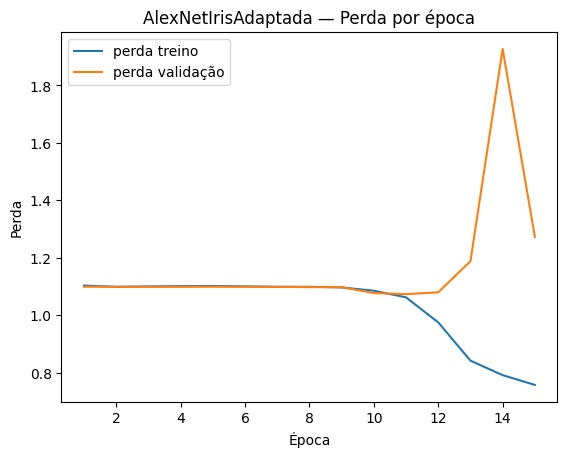

,epoca,perda_treino,acc_treino,perda_val,acc_val
0,1,1.103006,0.311594,1.098889,0.333333
1,2,1.098475,0.355072,1.098631,0.333333
2,3,1.099865,0.304348,1.098624,0.333333
3,4,1.100882,0.253623,1.098606,0.333333
4,5,1.101262,0.268116,1.098775,0.333333
5,6,1.100199,0.304348,1.098782,0.333333
6,7,1.098571,0.340580,1.098374,0.333333
7,8,1.098683,0.340580,1.097464,0.500000
8,9,1.096322,0.398551,1.097439,0.366667
9,10,1.084919,0.463768,1.076739,0.400000


In [8]:
import matplotlib.pyplot as plt

df_alexnet = pd.DataFrame(historico_alexnet)
df_alexnet.to_csv("historico_alexnet_iris.csv", index=False)

plt.plot(df_alexnet["epoca"], df_alexnet["perda_treino"], label="perda treino")
plt.plot(df_alexnet["epoca"], df_alexnet["perda_val"], label="perda validação")
plt.xlabel("Época")
plt.ylabel("Perda")
plt.legend()
plt.title("AlexNetIrisAdaptada — Perda por época")
plt.show()

df_alexnet


### Interpretando os resultados da AlexNet

A AlexNet é uma arquitetura muito maior que a `CNNIrisSimples`, mas aqui ela está sendo treinada **do zero**: usamos `weights=None`, portanto seus pesos começaram aleatórios. Com um conjunto pequeno de imagens, uma arquitetura maior não necessariamente apresentará um resultado melhor. Observe as curvas obtidas e guarde esse resultado para a comparação final.


## 7. Exemplo guiado 4 — Inspecionando e adaptando a ResNet18

A ResNet18 organiza sua estrutura de outra forma. Em vez de `features` e `classifier`, aparecem `conv1`, `layer1`, `layer2`, `layer3`, `layer4`, `avgpool` e `fc`.

Compare com o diagrama:

![Diagrama da ResNet18](https://drive.google.com/thumbnail?id=1cZAqyRbDb1Lg4DKEdXermk2WJ8o61V9F&sz=w1600)


In [9]:
from torchvision.models import resnet18

resnet18_base = resnet18(weights=None)
print(resnet18_base)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [10]:
resnet18_iris_adaptada = resnet18(weights=None)
n_entradas_fc = resnet18_iris_adaptada.fc.in_features
resnet18_iris_adaptada.fc = nn.Linear(n_entradas_fc, 3)
resnet18_iris_adaptada = resnet18_iris_adaptada.to(device)

print("Camada final original:", resnet18_base.fc)
print("Camada final adaptada:", resnet18_iris_adaptada.fc)


Camada final original: Linear(in_features=512, out_features=1000, bias=True)
Camada final adaptada: Linear(in_features=512, out_features=3, bias=True)


### Exercício 3 — Lendo o `print` da ResNet18

1. Quais grupos aparecem entre `layer1` e `layer4`?
2. Quantos `BasicBlock` existem em `layer1`? E em `layer2`, `layer3` e `layer4`?
3. Quantos `BasicBlock` existem no total?
4. Qual é o `in_channels` e o `out_channels` da `conv1`?
5. Qual é o `in_features` e o `out_features` da `fc` original?
6. O que mudou na `fc` adaptada?
7. No diagrama do `content.md`, onde aparece a ideia da **skip connection** que não era visível na AlexNet?
8. Por que não seria seguro assumir que a última camada de qualquer arquitetura sempre se chama `classifier[6]`?

**Sua resposta:**

1. `layer1`, `layer2`, `layer3` e `layer4`.
2. 2 em cada uma.
3. 8.
4. in é 3 e out é 64.
5. 512 e 1000, respectivamente.
6. Só o out que foi de 1000 para 3. O in continua 512.
7. Aparecem como setas que contornam as convoluções.
8. Porque muda de arquitetura para arquitetura.

## 8. Exemplo guiado 5 — Treinando a `ResNet18IrisAdaptada`


In [11]:
otimizador_resnet = optim.Adam(resnet18_iris_adaptada.parameters(), lr=1e-4)
historico_resnet = {"epoca": [], "perda_treino": [], "acc_treino": [], "perda_val": [], "acc_val": []}

for epoca in range(1, n_epocas + 1):
    resnet18_iris_adaptada.train()
    perda_total, acertos, total = 0.0, 0, 0

    for imagens, rotulos in loader_treino:
        imagens, rotulos = imagens.to(device), rotulos.to(device)
        otimizador_resnet.zero_grad()
        saidas = resnet18_iris_adaptada(imagens)
        perda = criterio(saidas, rotulos)
        perda.backward()
        otimizador_resnet.step()

        perda_total += perda.item() * imagens.size(0)
        acertos += (saidas.argmax(dim=1) == rotulos).sum().item()
        total += imagens.size(0)

    perda_treino = perda_total / total
    acc_treino = acertos / total

    resnet18_iris_adaptada.eval()
    perda_val_total, acertos_val, total_val = 0.0, 0, 0
    with torch.no_grad():
        for imagens, rotulos in loader_val:
            imagens, rotulos = imagens.to(device), rotulos.to(device)
            saidas = resnet18_iris_adaptada(imagens)
            perda = criterio(saidas, rotulos)
            perda_val_total += perda.item() * imagens.size(0)
            acertos_val += (saidas.argmax(dim=1) == rotulos).sum().item()
            total_val += imagens.size(0)

    perda_val = perda_val_total / total_val
    acc_val = acertos_val / total_val

    historico_resnet["epoca"].append(epoca)
    historico_resnet["perda_treino"].append(perda_treino)
    historico_resnet["acc_treino"].append(acc_treino)
    historico_resnet["perda_val"].append(perda_val)
    historico_resnet["acc_val"].append(acc_val)

    print(f"Época {epoca}: perda_treino={perda_treino:.4f} acc_treino={acc_treino:.4f} "
          f"perda_val={perda_val:.4f} acc_val={acc_val:.4f}")


Época 1: perda_treino=1.1589 acc_treino=0.3478 perda_val=1.0985 acc_val=0.3667
Época 2: perda_treino=0.4731 acc_treino=0.8913 perda_val=1.0982 acc_val=0.3667
Época 3: perda_treino=0.2408 acc_treino=0.9638 perda_val=1.1813 acc_val=0.3667
Época 4: perda_treino=0.1014 acc_treino=0.9783 perda_val=1.2715 acc_val=0.2333
Época 5: perda_treino=0.0979 acc_treino=0.9783 perda_val=1.2115 acc_val=0.3000
Época 6: perda_treino=0.0973 acc_treino=0.9710 perda_val=1.2139 acc_val=0.3333
Época 7: perda_treino=0.1260 acc_treino=0.9565 perda_val=1.2667 acc_val=0.3000
Época 8: perda_treino=0.0932 acc_treino=0.9783 perda_val=1.3265 acc_val=0.4000
Época 9: perda_treino=0.0667 acc_treino=0.9710 perda_val=1.3227 acc_val=0.4333
Época 10: perda_treino=0.0352 acc_treino=0.9928 perda_val=1.2980 acc_val=0.4333
Época 11: perda_treino=0.0868 acc_treino=0.9710 perda_val=1.3215 acc_val=0.3667
Época 12: perda_treino=0.0583 acc_treino=0.9638 perda_val=1.3853 acc_val=0.3667
Época 13: perda_treino=0.0710 acc_treino=0.9783 p

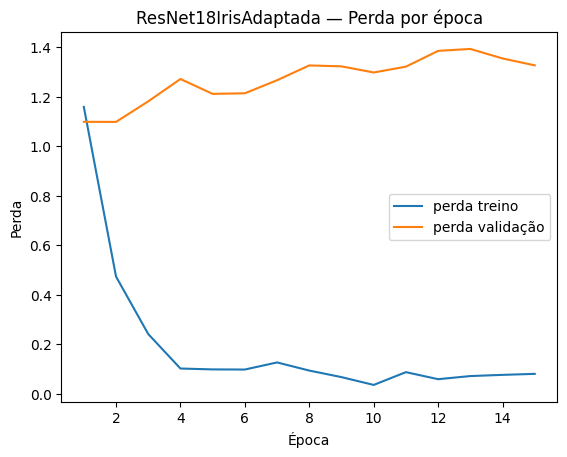

,epoca,perda_treino,acc_treino,perda_val,acc_val
0,1,1.158858,0.347826,1.098530,0.366667
1,2,0.473055,0.891304,1.098201,0.366667
2,3,0.240785,0.963768,1.181339,0.366667
3,4,0.101415,0.978261,1.271505,0.233333
4,5,0.097852,0.978261,1.211498,0.300000
5,6,0.097337,0.971014,1.213929,0.333333
6,7,0.126045,0.956522,1.266656,0.300000
7,8,0.093169,0.978261,1.326481,0.400000
8,9,0.066683,0.971014,1.322722,0.433333
9,10,0.035152,0.992754,1.297991,0.433333


In [12]:
df_resnet = pd.DataFrame(historico_resnet)
df_resnet.to_csv("historico_resnet18_iris.csv", index=False)

plt.plot(df_resnet["epoca"], df_resnet["perda_treino"], label="perda treino")
plt.plot(df_resnet["epoca"], df_resnet["perda_val"], label="perda validação")
plt.xlabel("Época")
plt.ylabel("Perda")
plt.legend()
plt.title("ResNet18IrisAdaptada — Perda por época")
plt.show()

df_resnet


### Interpretando os resultados da ResNet18

Assim como na AlexNet, a ResNet18 está sendo treinada **do zero**: `weights=None` significa que seus pesos começaram aleatórios. Portanto, uma arquitetura maior e mais sofisticada não garante, sozinha, melhor desempenho em um conjunto pequeno de imagens. Observe as curvas de treino e validação e guarde esse resultado para a comparação final.


## 9. Exemplo de erro comum — esquecer de adaptar a camada final

A célula abaixo cria uma AlexNet com 1000 saídas. A `CrossEntropyLoss` ainda consegue calcular a perda porque os rótulos 0, 1 e 2 são índices válidos dentro de 1000 posições. O erro, portanto, é **conceitual**, não necessariamente uma exceção do Python: estamos treinando uma rede cuja saída não representa o problema de três classes que queremos resolver.


In [13]:
modelo_com_erro = alexnet(weights=None).to(device)

print("Última camada NÃO adaptada:", modelo_com_erro.classifier[6])
print("Quantidade de saídas:", modelo_com_erro.classifier[6].out_features)

imagens, rotulos = next(iter(loader_treino))
imagens, rotulos = imagens.to(device), rotulos.to(device)

with torch.no_grad():
    saidas = modelo_com_erro(imagens)

print("Shape da saída:", saidas.shape)
print("Shape esperado para nosso problema: [B, 3]")


Última camada NÃO adaptada: Linear(in_features=4096, out_features=1000, bias=True)
Quantidade de saídas: 1000
Shape da saída: torch.Size([16, 1000])
Shape esperado para nosso problema: [B, 3]


### Exercício de correção de erro

1. Por que `[B, 1000]` não representa corretamente o problema de Iris?
2. Qual linha precisa ser executada para transformar essa saída em `[B, 3]`?
3. Por que esse erro pode passar despercebido sem gerar uma exceção na `CrossEntropyLoss`?

**Sua resposta:**

1. Porque o problema tem 3 classes.
2. `modelo_com_erro.classifier[6] = nn.Linear(modelo_com_erro.classifier[6].in_features, 3)`
3. Porque a ela aceita rótulos de 0 a 999, e os rótulos 0, 1 e 2 são índices válidos.


## 10. Exercício final — diagnóstico dirigido

Use os **prints, diagramas e resultados reais** produzidos neste laboratório:

1. Compare AlexNet e ResNet18 quanto à organização do `print`: quais nomes de blocos deixam claro que as duas arquiteturas foram implementadas de maneiras diferentes?
2. Cite o número de `Conv2d`, `MaxPool2d` e `Linear` que você identificou na AlexNet.
3. Cite o número total de `BasicBlock` identificado na ResNet18 e explique onde as conexões residuais aparecem no diagrama.
4. Compare a última camada original e adaptada das duas redes.
5. Compare `acc_treino` e `acc_val` da primeira e da última época de cada arquitetura.
6. O fato de `weights=None` muda como você interpreta o resultado? Explique.
7. AlexNet e ResNet18 conseguiram superar a `CNNIrisSimples`? Uma arquitetura maior e mais profunda garante um resultado melhor neste experimento? Justifique com os resultados obtidos.
8. O `print` de cada rede bate com o respectivo diagrama didático? Dê evidências concretas.

**Sua resposta:**

1. A AlexNet usa features, avgpool e classifier, enquanto a ResNet18 usa conv1, bn1, maxpool, layer1 a layer4 (com BasicBlock) e fc.
2. A AlexNet tem 5 Conv2d, 3 MaxPool2d e 3 Linear.
3. A ResNet18 tem 8 BasicBlock e as conexões residuais são atalhos que contornam os blocos somando a entrada à saída.
4. Na AlexNet, a camada Linear(4096, 1000) virou Linear(4096, 3). Na ResNet18, Linear(512, 1000) virou Linear(512, 3). Em ambas, só mudou o out_features.
5. Na época 1, a AlexNet teve 0.312/0.333 e na 15, 0.609/0.267. A ResNet18 teve 0.348/0.367 na época 1 e 0.957/0.500 na época 15.
6. Sim, com weights=None a rede começa totalmente aleatória e sofre com poucos dados (138 imagens), precisando aprender do zero.
7. Não superaram. No teste, a CNNIrisSimples fez 0.394, a AlexNet 0.273 e a ResNet18 empatou em 0.394, mostrando que redes maiores não garantem melhor resultado sem dados ou pré-treino suficientes.
8. Sim, o print bate com os diagramas, mostrando exatamente as 5 convoluções, 3 poolings e 3 lineares na AlexNet, e os blocos de camadas na ResNet18.

## 11. Desafio extra 1 (opcional) — Acurácia × custo de treino

Compare número de parâmetros. Se você quiser medir tempo, execute uma única época adicional e registre o valor.


In [14]:
comparacao_parametros = pd.DataFrame({
    "modelo": ["AlexNetIrisAdaptada", "ResNet18IrisAdaptada"],
    "parametros": [
        contar_parametros(alexnet_iris_adaptada),
        contar_parametros(resnet18_iris_adaptada),
    ],
})
comparacao_parametros


,modelo,parametros
0,AlexNetIrisAdaptada,57016131
1,ResNet18IrisAdaptada,11178051


**Pergunta:** o modelo com mais parâmetros foi necessariamente o que apresentou melhor validação? Use os seus próprios resultados.

**Sua resposta:**

Não. A AlexNet tem cerca de 57 milhões de parâmetros contra mas ou menos 11 milhões da ResNet18 e teve pior validação final (0.267 contra 0.500) e pior teste (0.273 contra 0.394).


## 12. Desafio extra 2 (opcional) — Adaptando LeNet e VGG16 para Iris

Agora você vai aplicar o raciocínio da lição em duas arquiteturas que não foram usadas no treino principal.

### 12.1 LeNet-5

A LeNet não existe como função pronta em `torchvision.models`, então abaixo fornecemos uma versão didática da arquitetura histórica. Ela foi escrita para **1 canal** e **10 classes**.

Sua tarefa é criar `LeNetIrisAdaptada` alterando apenas o necessário para:
- receber imagens RGB (`3` canais);
- produzir `3` saídas.

Para manter as dimensões históricas da LeNet, usaremos imagens `32 × 32` neste desafio.

![Diagrama da LeNet-5](https://drive.google.com/thumbnail?id=1K6oL_Xq3Yzcz9Z-XclZyLIsw9epPyhlJ&sz=w1600)


In [15]:
class LeNetBase(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.pool1 = nn.AvgPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.pool2 = nn.AvgPool2d(2, 2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = torch.tanh(self.conv1(x))
        x = self.pool1(x)
        x = torch.tanh(self.conv2(x))
        x = self.pool2(x)
        x = self.flatten(x)
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        return self.fc3(x)

print(LeNetBase())


LeNetBase(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


In [20]:
# TODO — crie sua versão adaptada sem copiar uma solução pronta.
# Compare o código acima com o problema de Iris.
#
class LeNetIrisAdaptada(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, kernel_size=5)
        self.pool1 = nn.AvgPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.pool2 = nn.AvgPool2d(2, 2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)

        self.fc3 = nn.Linear(84, 3)

    def forward(self, x):
        x = torch.tanh(self.conv1(x))
        x = self.pool1(x)
        x = torch.tanh(self.conv2(x))
        x = self.pool2(x)
        x = self.flatten(x)
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        return self.fc3(x)

# Depois:
lenet_iris = LeNetIrisAdaptada()
print(lenet_iris)


LeNetIrisAdaptada(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=3, bias=True)
)


**Antes de seguir, responda:** quais **duas dimensões conceituais** precisam mudar em relação à LeNet histórica? Localize essas mudanças no seu `print`.

**Sua resposta:**

Para o in: A LeNet original foi concebida para imagens em escala de cinza (1 canal), mas o dataset Iris utiliza imagens coloridas RGB (3 canais).
Para o out: A LeNet original foi projetada para classificar dígitos de 0 a 9 (10 classes), enquanto o problema de Iris possui apenas 3 classes (setosa, versicolor e virginica).

### 12.2 VGG16

A VGG16 existe em `torchvision.models`. Aqui o desafio é parecido com a AlexNet: inspecione a última camada e crie `vgg16_iris_adaptada` com 3 saídas.

![Diagrama da VGG16](https://drive.google.com/thumbnail?id=1pDKMqEqaPl77BAibZREX2NPwR230zvcr&sz=w1600)


In [21]:
from torchvision.models import vgg16

vgg16_base = vgg16(weights=None)
print("Última camada original:", vgg16_base.classifier[6])

# TODO:
vgg16_iris_adaptada = vgg16(weights=None)
n_entradas_vgg = vgg16_iris_adaptada.classifier[6].in_features
vgg16_iris_adaptada.classifier[6] = nn.Linear(n_entradas_vgg, 3)

print(vgg16_iris_adaptada)
print("\nCamada final adaptada da VGG16:", vgg16_iris_adaptada.classifier[6])

Última camada original: Linear(in_features=4096, out_features=1000, bias=True)
VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(i

**Perguntas do desafio:**

1. Quantas `Conv2d` aparecem na VGG16?
2. Quantas `MaxPool2d`?
3. Quantas `Linear` no `classifier`?
4. O que você precisou mudar para adaptar a rede a Iris?
5. Compare LeNet, AlexNet, VGG16 e ResNet18: qual delas parece mais simples de entender apenas olhando o `print`? Por quê?

**Sua resposta:**

1. Aparecem 13 camadas convolucionais (Conv2d) organizadas em blocos dentro do subgrupo features.
2. Aparecem 5 operações de pooling (MaxPool2d) intercaladas entre os blocos convolucionais.
3. Aparecem 3 camadas lineares (Linear), sendo duas ocultas de 4096 neurônios e a camada final de classificação.
4. Foi necessário acessar a última camada do classificador (vgg16_iris_adaptada.classifier[6]) e redimensionar o parâmetro de saída (out_features) de 1000 para 3, mantendo o in_features original.
5. A LeNet é a mais simples e direta de compreender pelo print, pois possui poucas camadas sequenciais e uma estrutura linear bem enxuta. Em contrapartida, VGG16 e ResNet18 geram saídas muito extensas devido à grande repetição de blocos convolucionais profundos.



## 13. Avaliação final e tabela comparativa


In [22]:
def avaliar_teste(modelo, loader):
    modelo.eval()
    acertos, total = 0, 0
    with torch.no_grad():
        for imagens, rotulos in loader:
            imagens, rotulos = imagens.to(device), rotulos.to(device)
            saidas = modelo(imagens)
            acertos += (saidas.argmax(dim=1) == rotulos).sum().item()
            total += imagens.size(0)
    return acertos / total

acc_teste_alexnet = avaliar_teste(alexnet_iris_adaptada, loader_teste)
acc_teste_resnet = avaliar_teste(resnet18_iris_adaptada, loader_teste)

print("Acurácia de teste — AlexNetIrisAdaptada:", acc_teste_alexnet)
print("Acurácia de teste — ResNet18IrisAdaptada:", acc_teste_resnet)


Acurácia de teste — AlexNetIrisAdaptada: 0.2727272727272727
Acurácia de teste — ResNet18IrisAdaptada: 0.3939393939393939


In [23]:
novas_linhas = pd.DataFrame({
    "modelo": ["AlexNetIrisAdaptada", "ResNet18IrisAdaptada"],
    "acuracia_teste": [acc_teste_alexnet, acc_teste_resnet],
})

tabela_final = pd.concat([resultados, novas_linhas], ignore_index=True)
nome_resultados_l04 = "resultados_modulo_m04.csv"
tabela_final.to_csv(nome_resultados_l04, index=False)
caminho_resultados_l04 = Path('/content/drive/MyDrive/dados_modulo_04') / nome_resultados_l04
caminho_resultados_l04.parent.mkdir(parents=True, exist_ok=True)
import shutil
shutil.copy2(nome_resultados_l04, caminho_resultados_l04)
print("Tabela da M04-L04 salva em:", caminho_resultados_l04)
tabela_final


Tabela da M04-L04 salva em: /content/drive/MyDrive/dados_modulo_04/resultados_modulo_m04.csv


,modelo,acuracia_teste
0,LogisticRegression,NaN
1,DecisionTreeClassifier,NaN
2,KNeighborsClassifier,NaN
3,MLP escolhida — Mais larga (5→16→3),1.000000
4,MLP escolhida regularizada — Mais larga (5→16→3),1.000000
5,CNNIrisSimples (imagem direta),0.393939
6,AlexNetIrisAdaptada,0.272727
7,ResNet18IrisAdaptada,0.393939


## 14. Reflexão final

1. Como AlexNet e ResNet18 se compararam com a `CNNIrisSimples` da M04-L03?
2. O que significa dizer que usamos uma arquitetura pronta, mas **não** pesos prontos?
3. Os resultados permitem concluir que AlexNet e ResNet18 "não funcionam"? Explique considerando o tamanho do conjunto de dados e o fato de os pesos terem sido aprendidos do zero.
4. O que este experimento mostra sobre a afirmação "uma arquitetura maior e mais sofisticada sempre produz resultados melhores"?
5. Qual informação você consegue descobrir apenas com `print(modelo)`?
6. Depois do segundo desafio, o que há de comum no processo de adaptação de AlexNet, VGG16 e ResNet18?

**Sua resposta:**

1. A AlexNet (0.273) foi pior que a CNN simples (0.394), e a ResNet18 (0.394) empatou com ela. Nenhuma ganhou, e as duas ficaram muito abaixo da MLP (1.0).
2. Arquitetura pronta é só a estrutura das camadas, que o TorchVision já deixa montada. Pesos prontos seriam valores já aprendidos em outro conjunto, como a ImageNet. Aqui usamos weights=None, então a estrutura veio pronta, mas os pesos começaram aleatórios e a rede aprendeu do zero.
3. Não dá para concluir isso. O conjunto é pequeno (138 imagens de treino e 33 de teste, e cada imagem de teste vale uns 3 pontos). Redes com milhões de parâmetros treinadas do zero tendem a decorar o treino: a ResNet chegou a 0.96 no treino e só 0.50 na validação. A AlexNet só saiu do acaso perto da época 10 de 15, então o treino ainda foi curto.
4. O experimento contradiz a ideia. A rede maior e mais sofisticada não superou nem a CNN simples, nem a MLP.
5. Com print(modelo) dá para ver a sequência de camadas, os tipos, os canais de entrada e saída, kernels, strides, paddings, a organização em blocos e o número de saídas. Não dá para ver o desempenho, os pesos treinados nem a lógica exata do forward (por exemplo, a soma da skip connection).
6. O processo é o mesmo nas três: achar a última camada (o nome muda: classifier[6] ou fc), ler o in_features dela, trocar por nn.Linear(in_features, 3) e deixar o resto da rede como está.


## 15. Checklist de conclusão

- [x] Carreguei `dataset_iris` e `comparacao_cnn_vs_mlp_m04l03.csv` da M04-L03.
- [x] Recriei os `DataLoader`s com imagens 64 × 64 usando a mesma divisão da M04-L03.
- [x] Entendi a diferença entre arquitetura pronta e pesos pré-treinados.
- [x] Analisei o `print` completo da AlexNet e comparei com o diagrama.
- [x] Criei e treinei a `AlexNetIrisAdaptada`.
- [x] Analisei a estrutura da ResNet18 e seus `BasicBlock`.
- [x] Criei e treinei a `ResNet18IrisAdaptada`.
- [x] Diagnostiquei o erro de manter 1000 saídas.
- [x] Respondi ao exercício final usando evidências do `print`, diagramas e resultados.
- [x] Tentei o desafio opcional com LeNet e VGG16.
- [x] Avaliei AlexNet e ResNet18 no teste.
- [x] Preenchi a reflexão final.


## 16. Orientação de entrega

Ao terminar:

1. Confira se todas as células obrigatórias foram executadas na ordem.
2. Confirme que `resultados_modulo_m04.csv` foi salvo em `Meu Drive/dados_modulo_04/` para a próxima lição e a geração de `historico_alexnet_iris.csv`, `historico_resnet18_iris.csv` e `resultados_modulo_m04.csv`.
3. Mantenha o notebook salvo no Google Drive.
4. Os desafios de LeNet e VGG16 são opcionais, mas devem permanecer no notebook se você os tiver realizado.
